# Лабораторная работа 2. Ранжирование признаков

|  |  |
|---|---|
| Дисциплина | Машинное обучение |
| Студент | Масенькин Максим |
| Группа | ПИбд-41 |
| Вариант | 20 |

## Задание

Используя код из пункта «Решение задачи ранжирования признаков», выполнить ранжирование
признаков с помощью моделей по варианту. Отобразить оценки каждого признака каждой моделью и
среднюю оценку, провести анализ получившихся результатов. Ответ — названия четырёх признаков,
оказавшихся самыми важными по среднему значению.

| Пункт задания | Вариант 20 |
|---|---|
| Данные | регрессионная проблема Фридмана, 750 объектов, 14 признаков (листинг 39) |
| Методы | линейная регрессия, гребневая регрессия, лассо, линейная корреляция (`f_regression`) |
| Параметры | `Ridge(alpha=7)`, `Lasso(alpha=0.05)`, как в листинге 40 |
| Ответ | четыре признака с наибольшей средней оценкой |
| Образец кода | пособие «Теория и практика машинного обучения», пункт «Решение задачи ранжирования признаков», стр. 205–212, листинги 38–50 |

## Ход работы

1. Сгенерировать данные по листингу 39 и разобрать, какие признаки влияют на выход.
2. Обучить четыре метода варианта и получить оценки важности признаков.
3. Привести оценки к общей шкале и вычислить среднюю оценку каждого признака.
4. Сверить расчёт с результатом пособия.
5. Определить четыре важнейших признака.
6. Сравнить полученное ранжирование с истинным вкладом признаков в выход.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import f_regression
from sklearn.linear_model import Lasso, LinearRegression, Ridge

from mllab.metrics import MEAN_COLUMN, ranking_table, top_features
from mllab.reporting import make_table


SIZE = 750
N_FEATURES = 14
SEED = 0  # np.random.seed(0) из листинга 39; нужен для сверки с листингом 46.
DEPENDENCE_NOISE = 0.025
RIDGE_ALPHA = 7.0
LASSO_ALPHA = 0.05
TOP = 4

NAMES = [f"x{i}" for i in range(1, N_FEATURES + 1)]

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 120)

## 1. Данные

Признаки $x_1, \dots, x_{14}$ — независимые случайные величины, равномерно распределённые на
отрезке $[0, 1]$. Выход вычисляется по формуле из листинга 39:

$$y = 10 \sin(\pi x_1 x_2) + 20 (x_3 - 0.5)^2 + 10 x_4 + 5 x_5^5 + \varepsilon .$$

От признаков $x_6, \dots, x_{10}$ выход не зависит, они добавлены как заведомо бесполезные.
Признаки $x_{11}, \dots, x_{14}$ после генерации перезаписываются копиями $x_1, \dots, x_4$ с
добавлением гауссова шума со стандартным отклонением 0.025. В формулу они не входят, но
коррелируют со своими оригиналами почти полностью. Задача ранжирования на таких данных имеет
известный правильный ответ, и можно проверить, какие методы его находят.

Листинг 39 отличается от формулы Фридмана в двух местах. В оригинальной постановке пятый признак входит линейно, как
$5 x_5$, а в пособии он возведён в пятую степень. Расчёт ниже выполнен по листингу: только при
$x_5^5$ средние оценки совпадают с листингом 46 пособия.

Второе отличие касается шума. Вызов `np.random.normal(0, 1)` без аргумента `size` возвращает одно
число, и ко всем 750 значениям выхода прибавляется одна и та же константа. Дисперсии она не
добавляет, поэтому выход полностью определяется признаками. Для сохранения совпадения с пособием
это поведение оставлено как есть.

Генератор инициализирован значением 0, как в листинге 39. Константа проекта
`RANDOM_STATE = 42` здесь не используется, т.к. с ней сверка с пособием была бы невозможна.

In [2]:
def friedman_problem(seed: int, x5_power: int = 5):
    rng = np.random.RandomState(seed)
    X = rng.uniform(0, 1, (SIZE, N_FEATURES))
    terms = {
        "10·sin(π·x1·x2)": 10 * np.sin(np.pi * X[:, 0] * X[:, 1]),
        "20·(x3 − 0.5)²": 20 * (X[:, 2] - 0.5) ** 2,
        "10·x4": 10 * X[:, 3],
        f"5·x5^{x5_power}" if x5_power != 1 else "5·x5": 5 * X[:, 4] ** x5_power,
    }
    shift = rng.normal(0, 1)
    y = sum(terms.values()) + shift
    X[:, 10:] = X[:, :4] + rng.normal(0, DEPENDENCE_NOISE, (SIZE, 4))
    return X, y, terms, shift


X, y, terms, shift = friedman_problem(SEED)

make_table(
    {
        "объектов": X.shape[0],
        "признаков": X.shape[1],
        "ε, одно значение на всю выборку": round(shift, 3),
        "дисперсия y": round(y.var(), 2),
        **{
            f"корреляция x{j + 1} и x{j + 11}": round(np.corrcoef(X[:, j], X[:, j + 10])[0, 1], 4)
            for j in range(4)
        },
    }
)

,значение
,
объектов,750
признаков,14
"ε, одно значение на всю выборку",0.355
дисперсия y,22.82
корреляция x1 и x11,0.9961
корреляция x2 и x12,0.9963
корреляция x3 и x13,0.9966
корреляция x4 и x14,0.9962


Корреляция в каждой паре «оригинал — копия» выше 0.996. Для линейной модели это практически один
и тот же столбец, и вес между ними можно поделить как угодно: качество от этого не изменится.

## 2. Методы оценки важности

Ранжировать признаки — значит расставить их по порядку наибольшего влияния на выход.
Для этого нужна числовая оценка, и у каждого метода она своя.

Три метода из четырёх строят линейную модель:

$$f(x) = w_0 + \sum_{j=1}^{14} w_j x_j .$$

Коэффициент $w_j$ показывает на сколько изменится предсказание, если увеличить $x_j$ на единицу и не
трогать остальные признаки. Чем больше $|w_j|$, тем сильнее признак влияет на ответ модели,
поэтому модуль коэффициента и берётся за оценку важности. Сравнивать коэффициенты между собой
можно, только если признаки в одной шкале. В нашем случае все признаки лежат на
отрезке $[0, 1]$.

Веса подбираются при обучении: модель ищет такие $w_j$, при которых заданная функция ошибки на
обучающей выборке минимальна. Три модели отличаются тем, какую функцию они минимизируют, и от этого
зависит, как они делят вес между почти одинаковыми признаками вроде $x_4$ и $x_{14}$.

### Линейная регрессия

Минимизирует сумму квадратов ошибок:

$$\sum_i \bigl(y_i - f(x_i)\bigr)^2 .$$

Это плоскость, к которой точки выборки в среднем ближе всего. Для двух почти одинаковых столбцов
сумма ошибок почти не меняется, если перераспределить вес между ними: веса $w_3 = 1,\ w_{13} = 0$
и $w_3 = 9,\ w_{13} = -8$ дают почти одинаковые предсказания. Какой вариант выберет модель, решают
мелкие случайные отклонения в данных. В итоге модули весов у дублей могут оказаться большими, хотя
вместе пара влияет на предсказание слабо, и важность по модулю веса получается ложной.

### Гребневая регрессия

К сумме квадратов ошибок добавляется штраф за большие веса (L2-штраф):

$$\sum_i \bigl(y_i - f(x_i)\bigr)^2 + \alpha \sum_j w_j^2 , \qquad \alpha = 7 .$$

Такой штраф называется регуляризацией: модель жертвует небольшой частью точности ради меньших
весов и вынуждена искать решение попроще. Параметр $\alpha$ задаёт силу штрафа: чем он больше, тем
сильнее веса прижимаются к нулю.

Квадратичный штраф выгоднее всего делить вес между дублями поровну. Пусть двум одинаковым
столбцам нужен суммарный вес 10:

- веса 10 и 0 дают штраф $10^2 + 0^2 = 100$;
- веса 5 и 5 дают штраф $5^2 + 5^2 = 50$.

Ошибка у обоих вариантов одна и та же, а штраф меньше у второго. Поэтому гребневая регрессия
даёт оригиналу и копии близкие веса и ни один вес не обращает в ноль.

### Лассо

Штрафуются модули весов (L1-штраф), а ошибка в scikit-learn дополнительно поделена на число
объектов $n$:

$$\frac{1}{2n} \sum_i \bigl(y_i - f(x_i)\bigr)^2 + \alpha \sum_j |w_j| , \qquad \alpha = 0.05 .$$

Для тех же двух столбцов:

- веса 10 и 0 дают штраф $|10| + |0| = 10$;
- веса 5 и 5 дают штраф $|5| + |5| = 10$.

Штраф не зависит от того, как разделён вес, и малейшее преимущество одного столбца в ошибке
делает выгодным решение, в котором вес второго равен нулю. Из-за излома модуля в нуле слабые веса
становятся равны нулю в точности, и лассо само отбирает признаки: из группы дублей обычно остаётся
один.

Из-за деления ошибки на $n$ значения $\alpha = 7$ у гребневой регрессии и $\alpha = 0.05$ у лассо
напрямую сравнивать нельзя.

### Линейная корреляция

Четвёртый метод `f_regression` модели не строит. Он берёт признаки по одному, считает для
каждого коэффициент корреляции Пирсона $r_j$ с выходом и пересчитывает его в F-статистику:

$$F_j = \frac{r_j^2}{1 - r_j^2}\,(n - 2).$$

Корреляция лежит от −1 до 1: значение 1 означает строгую возрастающую линейную связь, 0 —
отсутствие линейной связи, −1 — строгую убывающую. F-статистика переводит её в шкалу от нуля до
бесконечности с учётом размера выборки: чем сильнее линейная связь, тем больше $F_j$. Про
остальные признаки метод ничего не знает, поэтому копия информативного признака получает почти
такую же оценку, как оригинал.

Заодно метод возвращает p-value — вероятность случайно получить такое же или ещё большее $F_j$,
если на самом деле признак с выходом не связан. Обычно связь считают значимой при p-value меньше
0.05.

| Метод | Оценка важности | Как смотрит на признаки | Почти одинаковые признаки |
|---|---|---|---|
| Линейная | $\lvert w_j \rvert$ в `LinearRegression` | все сразу, без штрафа | делит вес произвольно, знаки могут гасить друг друга |
| Гребневая | $\lvert w_j \rvert$ в `Ridge(alpha=7)` | все сразу, штрафует квадраты весов | делит вес поровну |
| Лассо | $\lvert w_j \rvert$ в `Lasso(alpha=0.05)` | все сразу, штрафует модули весов | оставляет один, остальным ноль |
| Корреляция | $F_j$ из `f_regression` | каждый по отдельности | всем дублям почти одинаковая оценка |

In [3]:
models = {
    "Линейная": LinearRegression(),
    "Гребневая": Ridge(alpha=RIDGE_ALPHA),
    "Лассо": Lasso(alpha=LASSO_ALPHA),
}


def raw_scores(X, y):
    scores = {name: model.fit(X, y).coef_ for name, model in models.items()}
    scores["Корреляция"], p_values = f_regression(X, y, center=True)
    return scores, p_values


scores, p_values = raw_scores(X, y)

raw_table = pd.DataFrame(scores, index=pd.Index(NAMES, name="признак"))
raw_table["p-value"] = p_values
raw_table.round(3)

,Линейная,Гребневая,Лассо,Корреляция,p-value
признак,,,,,
x1,17.298,3.670,6.311,118.356,0.000
x2,10.592,3.611,6.611,174.133,0.000
x3,-8.812,-0.366,-0.000,0.802,0.371
x4,11.993,4.796,9.208,388.484,0.000
x5,3.379,2.938,2.704,14.529,0.000
x6,0.449,0.449,0.000,0.092,0.761
x7,0.149,0.203,0.000,5.012,0.025
x8,0.503,0.459,0.000,7.573,0.006
x9,0.071,0.078,0.000,2.925,0.088


In [4]:
make_table({name: round(model.score(X, y), 3) for name, model in models.items()}, column="R²")

,R²
,
Линейная,0.735
Гребневая,0.724
Лассо,0.722


Оценки разных методов лежат в очень разных диапазонах: коэффициенты линейных моделей не больше
17.3, а F-статистика у $x_4$ равна 388.5. Если усреднить их как есть, итог почти целиком определит
корреляция.

У линейной регрессии дубли получили веса разных знаков. У $x_3$ вес −8.81, у его копии $x_{13}$
+8.40. Столбцы почти одинаковы, поэтому эти слагаемые почти полностью компенсируют друг друга: по
отдельности веса большие, а вместе пара на предсказание почти не влияет. То же у $x_1$ и $x_{11}$:
+17.30 и −10.30. Это мультиколлинеарность, о которой говорилось ранее.

Лассо оставило ненулевые веса только у $x_1, x_2, x_4, x_5$, у остальных десяти признаков веса
равны нулю. Гребневая регрессия не обнулила ни одного веса, а оригиналам и копиям дала близкие
значения: 4.80 у $x_4$ и 4.42 у $x_{14}$.

У $x_3$ F-статистика всего 0.80 при p-value 0.371: тест не видит линейной связи $x_3$ с выходом,
хотя $x_3$ есть в формуле.

С шумовыми $x_7$ и $x_8$ ситуация обратная: их p-value 0.025 и 0.006 меньше 0.05, хотя в формулу
они не входят. Это случайные срабатывания теста. На итог они почти не влияют: их
F-статистики гораздо меньше, чем у $x_1$, $x_2$ и $x_4$, и после нормировки оценки близки к нулю.

Линейные модели объясняют около 73% разброса выхода ($R^2$ от 0.722 до 0.735). Шума в данных нет,
значит оставшиеся 27% приходятся на нелинейные части формулы, которые линейная модель описать не
может.

## 3. Приведение оценок к общей шкале

Перед усреднением оценки каждого метода переводятся в отрезок $[0, 1]$ преобразованием
`MinMaxScaler`:

$$s'_j = \frac{|s_j| - \min_k |s_k|}{\max_k |s_k| - \min_k |s_k|}.$$

Самый важный признак метода получает 1, самый слабый 0, остальные получают промежуточные значения в
том же порядке. После этого оценки всех методов в одной шкале, и их можно усреднять. Это делает
функция `mllab.metrics.ranking_table`: она нормирует оценки каждого метода и добавляет столбец
среднего. 

In [5]:
ranking = ranking_table(scores, NAMES)
ranking.round(2)

,Линейная,Гребневая,Лассо,Корреляция,среднее
признак,,,,,
x4,0.69,1.00,1.00,1.00,0.92
x1,1.00,0.76,0.69,0.30,0.69
x2,0.61,0.75,0.72,0.45,0.63
x14,0.12,0.92,0.00,0.98,0.51
x11,0.59,0.59,0.00,0.29,0.37
x12,0.19,0.67,0.00,0.44,0.33
x5,0.19,0.61,0.29,0.04,0.28
x3,0.51,0.06,0.00,0.00,0.14
x13,0.48,0.00,0.00,0.00,0.12


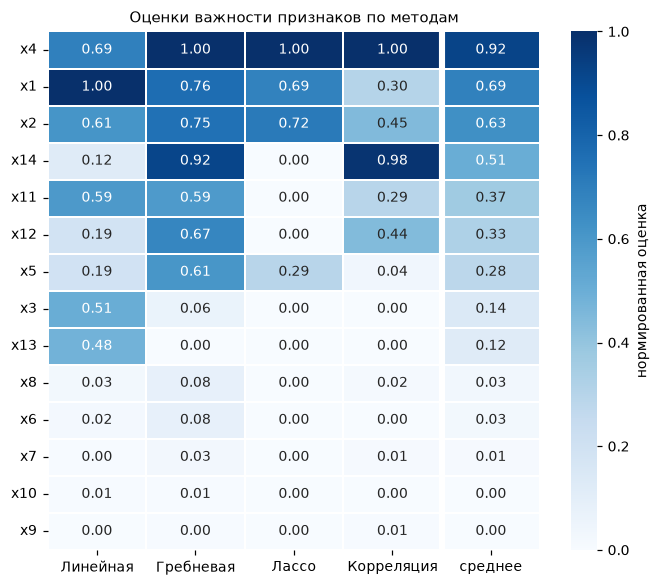

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 5.4))
sns.heatmap(
    ranking,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "нормированная оценка"},
    ax=ax,
)
ax.axvline(ranking.shape[1] - 1, color="white", linewidth=4)
ax.set_title("Оценки важности признаков по методам")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

Признаки упорядочены по средней оценке. Нижняя часть карты, где собраны шумовые $x_6, \dots,
x_{10}$, светлая во всех столбцах, то есть бесполезные признаки распознали все четыре метода. Методы согласны только насчёт $x_4$, остальные строки окрашены в столбцах
по-разному.

## 4. Сверка с пособием

В пособии усреднены три модели, без корреляции. Среднее по тем же
трём столбцам должно совпасть с листингом 46. Для сравнения тот же расчёт выполнен по формуле
Фридмана со слагаемым $5 x_5$.

In [7]:
LISTING_46 = {
    "x4": 0.90, "x1": 0.82, "x2": 0.69, "x11": 0.39, "x5": 0.36, "x14": 0.35, "x12": 0.29,
    "x3": 0.19, "x13": 0.16, "x8": 0.04, "x6": 0.03, "x10": 0.01, "x7": 0.01, "x9": 0.00,
}  # fmt: skip


def textbook_mean(x5_power):
    X_check, y_check, _, _ = friedman_problem(SEED, x5_power=x5_power)
    table = ranking_table(raw_scores(X_check, y_check)[0], NAMES)
    return table[list(models)].round(2).mean(axis=1).round(2)


check = pd.DataFrame(
    {"листинг 46": LISTING_46, "5·x5^5": textbook_mean(5), "5·x5": textbook_mean(1)},
    index=list(LISTING_46),
).rename_axis("признак")
check.round(2)

,листинг 46,5·x5^5,5·x5
признак,,,
x4,0.90,0.90,0.86
x1,0.82,0.82,0.85
x2,0.69,0.69,0.71
x11,0.39,0.39,0.40
x5,0.36,0.36,0.55
x14,0.35,0.35,0.37
x12,0.29,0.29,0.27
x3,0.19,0.19,0.18
x13,0.16,0.16,0.17


In [8]:
make_table(
    {
        f"макс. разница с листингом 46, {column}": round(
            (check[column] - check["листинг 46"]).abs().max(), 3
        )
        for column in ("5·x5^5", "5·x5")
    }
)

,значение
,
"макс. разница с листингом 46, 5·x5^5",0.0
"макс. разница с листингом 46, 5·x5",0.19


Перед усреднением каждая оценка округлена до сотых, как в листинге 43. С формулой листинга 39
совпали все 14 значений: данные и модели воспроизведены точно, а перенос кода с Python 2 ничего
не изменил. С формулой Фридмана среднее для $x_5$ расходится на 0.19, так что $5 x_5^5$ — не
опечатка в листинге, именно по этой формуле и получены числа листинга 46.

## 5. Ответ на задание

Ответ составляют четыре признака с наибольшим средним по четырём методам варианта.

In [9]:
answer = top_features(ranking, TOP)
make_table(
    {
        f"{place}. {name}": ranking.loc[name, MEAN_COLUMN].round(2)
        for place, name in enumerate(answer, start=1)
    },
    column="средняя оценка",
)

,средняя оценка
,
1. x4,0.92
2. x1,0.69
3. x2,0.63
4. x14,0.51


Четыре важнейших признака по средней оценке: $x_4$, $x_1$, $x_2$ и $x_{14}$.

Добавление корреляции изменило ответ по сравнению с пособием. У трёх моделей пособия четвёртое
место занимал $x_{11}$ со средней оценкой 0.39, а $x_{14}$ был шестым с 0.35. Корреляция дала
$x_{14}$ оценку 0.98, и его среднее выросло до 0.51.

## 6. Сравнение с истинной важностью

Формула выхода известна, поэтому вклад каждого признака можно измерить напрямую. Слагаемые
формулы зависят от непересекающихся групп независимых признаков, поэтому дисперсия выхода
примерно равна сумме дисперсий слагаемых. Доля дисперсии слагаемого показывает, какую часть
разброса выхода оно объясняет.

In [10]:
def variance_shares(terms, y):
    return pd.Series({name: values.var() / y.var() for name, values in terms.items()})


shares = variance_shares(terms, y)
make_table(
    {**shares.round(3).to_dict(), "сумма": shares.sum().round(3)}, column="доля дисперсии y"
)

,доля дисперсии y
,
10·sin(π·x1·x2),0.478
20·(x3 − 0.5)²,0.096
10·x4,0.381
5·x5^5,0.074
сумма,1.029


Сумма долей равна 1.029. Небольшое превышение единицы скорее всего связано с тем, что на выборке из 750
объектов слагаемые слегка коррелируют между собой, хотя теоретически независимы.

Самое влиятельное слагаемое — синус от произведения $x_1 x_2$ (48% дисперсии), его влияние
поровну делят $x_1$ и $x_2$. Затем идёт $x_4$ (38%), и только потом $x_3$ (10%) и $x_5$ (7%).
Истинный порядок признаков поэтому выглядит так: $x_4$, затем $x_1$ и $x_2$, затем $x_3$ и
$x_5$. Признаки $x_6, \dots, x_{14}$ в формулу не входят.

Первые три места ответа с этим порядком совпадают. Четвёртое место занял $x_{14}$, которого в
формуле нет, а $x_3$ с десятью процентами дисперсии оказался на восьмом месте. Обе ошибки
объясняются тем, как устроены методы.

### Почему линейные методы не видят $x_3$

Все четыре метода ищут прямую зависимость: признак растёт — выход растёт или падает. У $x_3$
зависимость другая. Слагаемое $20 (x_3 - 0.5)^2$ — парабола: в середине отрезка оно равно нулю, а
чем дальше $x_3$ от середины, тем оно больше. Прямой такую зависимость не описать. На графиках ниже
точками показана выборка, линией — средний выход на каждой десятой части отрезка.

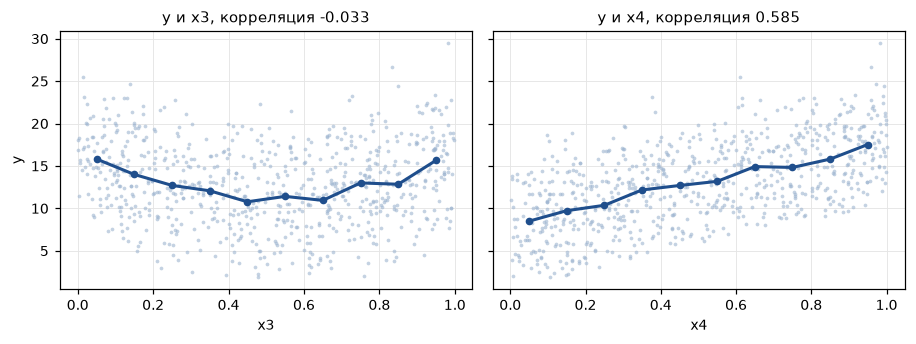

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2), sharey=True)
bins = np.linspace(0, 1, 11)
centers = (bins[:-1] + bins[1:]) / 2

for ax, j in zip(axes, (2, 3), strict=True):
    feature = X[:, j]
    band_means = pd.Series(y).groupby(np.digitize(feature, bins[1:-1])).mean()
    ax.scatter(feature, y, s=6, color="#9db4d0", alpha=0.6, linewidths=0)
    ax.plot(centers, band_means, color="#1f4e8c", linewidth=2, marker="o", markersize=4)
    ax.set_title(f"y и x{j + 1}, корреляция {np.corrcoef(feature, y)[0, 1]:.3f}")
    ax.set_xlabel(f"x{j + 1}")
    ax.grid(color="#e5e5e5", linewidth=0.6)
    ax.set_axisbelow(True)

axes[0].set_ylabel("y")
fig.tight_layout()
plt.show()

In [12]:
make_table(
    {
        "корреляция y и x3": round(np.corrcoef(X[:, 2], y)[0, 1], 3),
        "корреляция y и (x3 − 0.5)²": round(np.corrcoef((X[:, 2] - 0.5) ** 2, y)[0, 1], 3),
    }
)

,значение
,
корреляция y и x3,-0.033
корреляция y и (x3 − 0.5)²,0.343


Для $x_3$ средний выход образует букву U, для $x_4$ растёт почти по прямой. Корреляция выхода с
$x_3$ почти нулевая (−0.033), хотя влияние есть: с $(x_3 - 0.5)^2$ корреляция уже 0.343. Поэтому
лассо обнулило $x_3$, гребневая регрессия дала ему 0.06, корреляция — 0.

У линейной регрессии оценка $x_3$ высокая, 0.51, но это следствие копии $x_{13}$: веса пары
большие и разного знака и компенсируют друг друга (п. 2). Реального влияния признака эта оценка не
показывает.

### Почему копия $x_4$ попала в ответ

$x_{14}$ — почти точная копия $x_4$, и два метода из четырёх их почти не различают. Корреляция
оценивает каждый признак отдельно и даёт копии почти ту же оценку, что оригиналу: 0.98 против
1.00. Гребневая регрессия делит вес между копией и оригиналом поровну: 0.92 против 1.00. Лассо
оставило только оригинал, линейная регрессия дала копии 0.12, но в среднем $x_{14}$ всё равно
обогнал $x_5$ и остальные копии.

В итоге в ответе три настоящих признака и одна копия. Для модели $x_{14}$ бесполезен: всё, что в
нём есть, уже есть в $x_4$.

### Признак $x_5$

Слагаемое $5 x_5^5$ почти равно нулю на большей части отрезка и резко растёт только у $x_5$,
близких к 1. Прямой такая зависимость описывается плохо, поэтому линейные методы оценили $x_5$
ниже, чем можно ожидать по его доле в разбросе выхода (7%), и в среднем он оказался на седьмом
месте.

## Выводы

1. Четыре важнейших признака по средней оценке четырёх методов — $x_4$, $x_1$, $x_2$ и
   $x_{14}$.
2. Среднее по трём моделям пособия совпало с листингом 46 во всех 14 значениях. С формулой
   Фридмана совпадения нет, значит слагаемое $5 x_5^5$ заложено в сам расчёт пособия. Шума в
   данных нет: `np.random.normal(0, 1)` прибавляет ко всему выходу одну константу.
3. Ранжирование верно отделило шумовые признаки $x_6, \dots, x_{10}$ и верно определило
   лидеров $x_4$, $x_1$, $x_2$. Признак $x_3$ все методы недооценили: выход зависит от него по
   параболе, а методы ищут прямую зависимость.
4. Копии признаков искажают ответ. $x_{14}$ попал в четвёрку, потому что корреляция и гребневая
   регрессия почти не отличают его от $x_4$. Лассо оставило только оригиналы, а линейная
   регрессия раздала оригиналам и копиям непредсказуемые веса.
5. Методы с одинаковым видом модели дают разные ранжирования, и усреднение сглаживает их
   крайности. Оно же переносит в ответ ошибки большинства, как случилось с $x_{14}$.

## Контрольные вопросы

**1. В чём суть задачи ранжирования признаков?**

Задача состоит в том, чтобы каждому признаку сопоставить числовую оценку его влияния на целевую
переменную и упорядочить признаки по этой оценке. Результат применяется при отборе признаков:
слабые исключаются, модель становится проще, обучается быстрее и меньше переобучается. Кроме
того, ранжирование помогает понять, от чего в действительности зависит изучаемая величина.

Оценки разных методов измеряют разное: модуль коэффициента модели, силу линейной связи, частоту
выбора признака и т. д. Чтобы их объединить, оценки приводят к общей шкале, в этой работе
преобразованием `MinMaxScaler`, и усредняют.

**2. Подробнее об использованных моделях.**

Линейная регрессия подбирает коэффициенты $w_j$ линейной функции так, чтобы сумма квадратов
ошибок на обучающей выборке была минимальной. Решение единственно и находится аналитически. При
сильно коррелированных признаках оно неустойчиво: близкие по качеству решения сильно различаются
коэффициентами, что и наблюдалось на парах $x_3$, $x_{13}$ и $x_1$, $x_{11}$.

Гребневая регрессия добавляет к сумме квадратов ошибок штраф $\alpha \sum_j w_j^2$. Он уменьшает
коэффициенты, делает решение устойчивым к мультиколлинеарности и делит вес между
коррелированными признаками поровну, но ни один коэффициент не обращает в ноль.

Лассо штрафует сумму модулей коэффициентов $\alpha \sum_j |w_j|$. Из-за излома этого штрафа в нуле
часть коэффициентов становится равна нулю в точности, и модель сама отбирает признаки. Из группы
коррелированных признаков лассо обычно оставляет один.

Функция `f_regression` моделью не является. Для каждого признака отдельно она вычисляет
корреляцию Пирсона с выходом и переводит её в F-статистику.
Метод быстрый и наглядный, но не учитывает другие признаки, поэтому копии информативного
признака получают такую же высокую оценку, как оригинал.

**3. В чём суть регрессионной проблемы Фридмана?**

Это синтетическая регрессионная задача для проверки
методов регрессии. Признаки равномерно распределены на $[0, 1]$, а выход задан известной формулой. В ней собраны разные
виды зависимости: взаимодействие двух признаков внутри синуса, квадратичная парабола, два
линейных слагаемых. Признаки начиная с шестого в формулу не входят.

Для задачи ранжирования она удобна тем, что правильный ответ известен заранее: важны $x_1, \dots,
x_5$, остальные бесполезны. В пособии задача усложнена копиями $x_{11}, \dots, x_{14}$ первых
четырёх признаков, что позволяет увидеть, как методы обходятся со взаимозависимыми признаками.
Квадратичное слагаемое при этом проверяет, способен ли метод заметить нелинейную зависимость, и
линейные методы этой проверки не прошли.